In [10]:
import numpy as np
import matplotlib.pyplot as plt
import torch

torch.manual_seed(0)

In [11]:
# сама функция потерь
def f(w):
    return torch.sin(w[0, 0]) * torch.cos(w[0, 1])

def closure():
    opt.zero_grad()
    loss = f(w)
    loss.backward()
    return loss
# один запуск оптимизатора
def run_opt(name, cls, epochs=1000, lr=0.1):
    w = torch.tensor([[10.0, 10.0]], dtype=torch.float64, requires_grad=True)
    opt = cls([w], lr=lr)
    traj = []

    for i in range(epochs):
        if name == "LBFGS":
            closure()
            opt.step(closure)
        else:
            opt.zero_grad()
            loss = f(w)
            loss.backward()
            opt.step()

        traj.append((w[0, 0].item(), w[0, 1].item(), f(w).item()))

    return np.array(traj), f(w).item()

In [12]:
names = []
for name in dir(torch.optim):
    obj = getattr(torch.optim, name)
    if isinstance(obj, type) and issubclass(obj, torch.optim.Optimizer) and obj is not torch.optim.Optimizer:
        names.append(name)

print("найдено:", names)

results = []
trajs = {}

for name in names:
    if name == "SparseAdam":
        print("SparseAdam skip: dense gradients")
        continue

    try:
        traj, loss = run_opt(name, getattr(torch.optim, name))
        results.append((name, loss, traj[-1, 0], traj[-1, 1]))
        trajs[name] = traj
    except Exception as e:
        print(name, "skip:", e)

print(f"\n{'optimizer':12} {'loss':>10} {'x':>8} {'y':>8}")
for name, loss, x, y in sorted(results, key=lambda z: z[1]):
    print(f"{name:12} {loss:10.6f} {x:8.4f} {y:8.4f}")

найдено: ['ASGD', 'Adadelta', 'Adafactor', 'Adagrad', 'Adam', 'AdamW', 'Adamax', 'LBFGS', 'Muon', 'NAdam', 'RAdam', 'RMSprop', 'Rprop', 'SGD', 'SparseAdam']
LBFGS skip: name 'opt' is not defined
SparseAdam skip: dense gradients

optimizer          loss        x        y
Adam          -1.000000   7.8540   9.4248
Adamax        -1.000000   7.8540   9.4248
NAdam         -1.000000   7.8540   9.4248
RAdam         -1.000000   7.8540   9.4248
SGD           -1.000000   7.8540   9.4248
Adagrad       -1.000000   7.8540   9.4248
Rprop         -1.000000   7.8540   9.4248
ASGD          -0.999999   7.8532   9.4238
AdamW         -0.999978   7.8494   9.4199
RMSprop       -0.997436   7.9081   9.3778
Adafactor     -0.989922   7.9316   9.5439
Muon          -0.584850   4.0906   5.5155
Adadelta      -0.076758   9.3019  10.3188


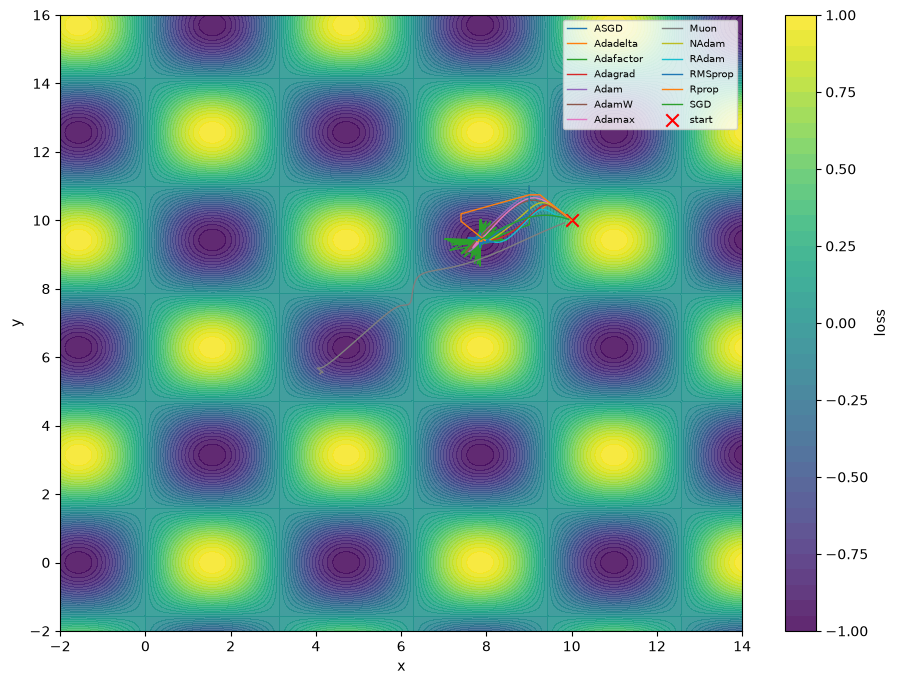

In [18]:
# поле потерь / траекторий
xx = np.linspace(-2, 14, 300)
yy = np.linspace(-2, 16, 300)
X, Y = np.meshgrid(xx, yy)
Z = np.sin(X) * np.cos(Y)

plt.figure(figsize=(11, 8))
plt.contourf(X, Y, Z, levels=40, cmap="viridis", alpha=0.85)
plt.colorbar(label="loss")

for name, traj in trajs.items():
    plt.plot(traj[:, 0], traj[:, 1], lw=1, label=name)

plt.scatter([10], [10], c="red", marker="x", s=80, label="start")
plt.xlim(-2, 14)
plt.ylim(-2, 16)
plt.xlabel("x")
plt.ylabel("y")
plt.legend(fontsize=7, ncol=2)
plt.show()

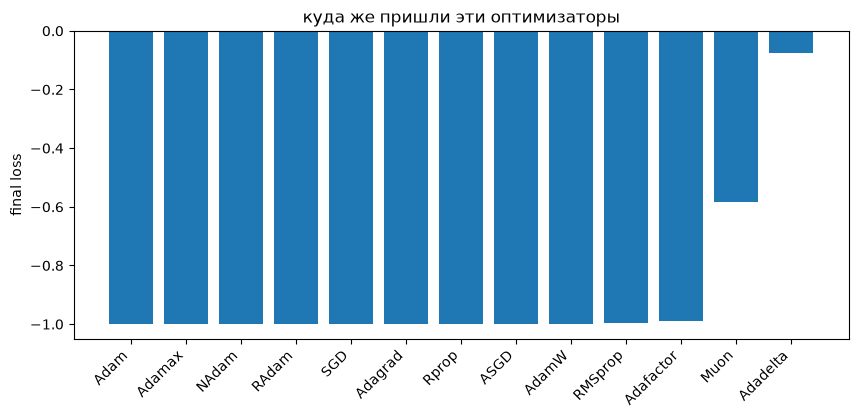

In [17]:
res = sorted(results, key=lambda z: z[1])
plt.figure(figsize=(10, 4))
plt.bar([r[0] for r in res], [r[1] for r in res])
plt.xticks(rotation=45, ha="right")
plt.ylabel("final loss")
plt.title("куда же пришли эти оптимизаторы")
plt.show()